# Lake Kariba night lights: cleaning the data points

This notebook cleans the NASA Black Marble **VNP46A1** night-light files for Lake Kariba and produces one clean table of light points, ready for DBSCAN.

The cleaning happens at three levels:

1. **Files**: drop files that are not VNP46A1, are empty, are an older copy of the same night, or do not cover the lake.
2. **Pixels**: inside each night, drop pixels that are missing, impossible, cloudy, cirrus, daytime, outside the lake, or flagged by the sensor. Drop whole nights with too little clear lake.
3. **Points**: from the lights found on each night, drop missing values, exact duplicates, twin-pixel duplicates, points outside the lake, and implausible values. Flag points next to the shore.

Every step reports how many rows it removed, so the cleaning can be checked and explained.

Outputs (in `OUTPUT_FOLDER`):
- `kariba_clean_points.csv`: the cleaned points, one row per light per night.
- `kariba_nightly_qc.csv`: one row per file, saying whether the night was used and why.
- `kariba_cleaning_log.csv`: how many rows each point-cleaning step removed.

## 1. Libraries

- `h5py` reads the `.h5` satellite files.
- `numpy` and `pandas` handle the grids and tables.
- `matplotlib.path.Path` tests whether a pixel is inside the lake outline.
- `scipy.ndimage` finds touching pixels (twin-pixel duplicates) and the shoreline.
- `skimage.feature.peak_local_max` finds the bright spots (lights).
- `matplotlib.pyplot` draws the checks at the end.

In [ ]:
import json
import re
from datetime import datetime, timedelta
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.path import Path as Outline
from scipy import ndimage
from skimage.feature import peak_local_max

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

## 2. Settings

Change the three folders to match your computer. The other values are the cleaning rules.

| Setting | Meaning | Why |
|---|---|---|
| `CLOUD_OK_VALUES` | cloud-mask values kept: 0 = confidently clear, 1 = probably clear | cloud blurs and hides lights |
| `DROP_CIRRUS` | also drop thin high cloud (cirrus) | cirrus is missed by the main cloud flag but still spreads light |
| `STRICT_DNB` | drop every pixel the sensor flagged, not only missing ones | off by default until the flag meanings are checked for this product version |
| `MIN_CLEAR_FRACTION` | skip a night if less than this share of the lake is usable | a night that is mostly cloud gives misleading counts |
| `MAX_MOON` | skip nights brighter than this moon illumination (`None` = keep all) | moonlight raises the background |
| `K_MAD`, `ABS_FLOOR` | light threshold = max(median + K × robust sigma, floor) | each night is judged against its own dark water |
| `MAX_RADIANCE` | values above this are treated as errors | no real light on the lake is this bright |
| `PEAK_MIN_DISTANCE_PIXELS` | minimum gap between two lights | 1 pixel keeps neighbouring boats apart |
| `SHORE_BUFFER_PIXELS` | pixels from land that count as "near shore" | glow from towns spills onto the water near the shore |
| `DROP_NEAR_SHORE` | remove near-shore points instead of only flagging them | kept by default so they can be reviewed |

In [ ]:
NIGHTS_FOLDER = Path.home() / "kariba" / "nights"
LAKE_FILE = Path.home() / "kariba_zone_and_basins" / "kariba_basins.json"
OUTPUT_FOLDER = Path.home() / "kariba-cleaning" / "out"

LAKE_NAME = "kariba"
CLOUD_OK_VALUES = (0, 1)
DROP_CIRRUS = True
STRICT_DNB = False
MIN_CLEAR_FRACTION = 0.5
MAX_MOON = None
K_MAD = 5.0
ABS_FLOOR = 1.5
MAX_RADIANCE = 10000.0
PEAK_MIN_DISTANCE_PIXELS = 1
SHORE_BUFFER_PIXELS = 1
DROP_NEAR_SHORE = False
WINDOW_MARGIN_PIXELS = 10

RADIANCE = "DNB_At_Sensor_Radiance"
CLOUD_MASK = "QF_Cloud_Mask"
DNB_QUALITY = "QF_DNB"
MOON = "Moon_Illumination_Fraction"
GRID_PATH = "HDFEOS/GRIDS/VIIRS_Grid_DNB_2d/Data Fields/"

OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)
print("Nights folder:", NIGHTS_FOLDER, "| exists:", NIGHTS_FOLDER.exists())
print("Lake file:", LAKE_FILE, "| exists:", LAKE_FILE.exists())
print("Output folder:", OUTPUT_FOLDER)

Nights folder: /home/Student/kariba/nights | exists: True
Lake file: /home/Student/kariba_zone_and_basins/kariba_basins.json | exists: True
Output folder: /home/Student/kariba-cleaning/out


## 3. File-level cleaning: which files to use

Each file name holds the product, the night (year and day of year), the tile, the collection and when NASA produced it, for example `VNP46A1.A2019032.h20v10.002.2024253154320.h5`.

This cell:
1. lists every `.h5` file in the folder;
2. **drops files whose name is not a VNP46A1 file** (for example a renamed or unrelated file);
3. **drops empty files** (an interrupted download);
4. **drops older copies of the same night and tile**, keeping the newest production. NASA reprocesses nights, and the same night must not be counted twice.

The table at the end shows how many files each rule removed.

In [ ]:
FILE_PATTERN = re.compile(
    r"^(?P<product>VNP46A1|VJ146A1)\.A(?P<year>\d{4})(?P<doy>\d{3})\."
    r"h(?P<h>\d{2})v(?P<v>\d{2})\.(?P<collection>\d{3})\.(?P<produced>\d{13})\.h5$"
)


def parse_filename(name):
    match = FILE_PATTERN.match(name)
    if match is None:
        return None
    day = datetime(int(match["year"]), 1, 1) + timedelta(days=int(match["doy"]) - 1)
    return {
        "Filename": name,
        "Date": day.strftime("%Y-%m-%d"),
        "Tile": f"h{match['h']}v{match['v']}",
        "Collection": match["collection"],
        "Produced": match["produced"],
    }


qc_rows = []
good_files = []
for path in sorted(NIGHTS_FOLDER.glob("*.h5")):
    info = parse_filename(path.name)
    if info is None:
        qc_rows.append({"Filename": path.name, "Status": "skipped: name is not a VNP46A1 file"})
        continue
    if path.stat().st_size == 0:
        qc_rows.append({"Filename": path.name, "Date": info["Date"], "Status": "skipped: empty file"})
        continue
    info["Path"] = path
    good_files.append(info)

files = pd.DataFrame(good_files)
if files.empty:
    raise FileNotFoundError(f"No VNP46A1 .h5 files in {NIGHTS_FOLDER}")

files = files.sort_values(["Date", "Tile", "Collection", "Produced"])
newest = files.drop_duplicates(["Date", "Tile"], keep="last")
for _, old in files.drop(newest.index).iterrows():
    qc_rows.append({"Filename": old["Filename"], "Date": old["Date"], "Status": "skipped: older copy of the same night"})
files = newest.reset_index(drop=True)

file_summary = pd.Series([row["Status"] for row in qc_rows], dtype="object").value_counts()
print(f"Files found: {len(files) + len(qc_rows)} | kept: {len(files)} | dropped: {len(qc_rows)}")
print(file_summary.to_string() if len(file_summary) else "No files dropped")
print(f"Nights from {files['Date'].min()} to {files['Date'].max()}, tiles: {sorted(files['Tile'].unique())}")

Files found: 1097 | kept: 1097 | dropped: 0
No files dropped
Nights from 2018-12-31 to 2022-01-01, tiles: ['h20v10']


## 4. The lake outline

The lake polygon decides which pixels are water. The cell accepts either:
- your `kariba_basins.json` (the five basins together make the lake), or
- a Natural Earth lakes GeoJSON, where the feature whose name contains "kariba" is used.

Islands (holes in a polygon) are treated as land. `inside_lake` returns True for every pixel centre that is on the lake.

In [ ]:
def polygons_from(geometry):
    if geometry["type"] == "Polygon":
        return [geometry["coordinates"]]
    if geometry["type"] == "MultiPolygon":
        return list(geometry["coordinates"])
    return []


def load_lake(path, lake_name):
    data = json.loads(Path(path).read_text(encoding="utf-8"))
    if "basins" in data:
        geometries = [basin["boundary"] for basin in data["basins"]]
    elif data.get("type") == "FeatureCollection":
        features = data.get("features", [])
        named = [f for f in features if lake_name in str(f.get("properties", {}).get("name", "")).casefold()]
        geometries = [f["geometry"] for f in (named or (features if len(features) == 1 else []))]
    elif data.get("type") == "Feature":
        geometries = [data["geometry"]]
    else:
        geometries = [data]
    polygons = [polygon for geometry in geometries for polygon in polygons_from(geometry)]
    if not polygons:
        raise ValueError(f"No lake polygon for '{lake_name}' in {path}")
    return polygons


def inside_lake(polygons, lon, lat):
    points = np.column_stack([lon.ravel(), lat.ravel()])
    inside = np.zeros(len(points), dtype=bool)
    for polygon in polygons:
        in_polygon = Outline(np.asarray(polygon[0])[:, :2]).contains_points(points)
        for hole in polygon[1:]:
            in_polygon &= ~Outline(np.asarray(hole)[:, :2]).contains_points(points)
        inside |= in_polygon
    return inside.reshape(lon.shape)


lake_polygons = load_lake(LAKE_FILE, LAKE_NAME)
corners = np.vstack([np.asarray(p[0])[:, :2] for p in lake_polygons])
LAKE_BOUNDS = (corners[:, 0].min(), corners[:, 1].min(), corners[:, 0].max(), corners[:, 1].max())
print(f"Lake polygons: {len(lake_polygons)}")
print("Lake bounds (lon_min, lat_min, lon_max, lat_max):", [round(v, 3) for v in LAKE_BOUNDS])

Lake polygons: 5
Lake bounds (lon_min, lat_min, lon_max, lat_max): [np.float64(26.986), np.float64(-17.974), np.float64(29.043), np.float64(-16.49)]


## 5. Reading only the lake area of each file

A VNP46A1 tile is a 2400 × 2400 grid covering 10° × 10°. Lake Kariba is a small part of it, so:

- `build_window` reads the file's own `lat` and `lon` lists once per tile, keeps only the rows and columns around the lake (plus a small margin), and marks which of those pixels are on the lake. A tile that does not contain the lake returns `None`, and its files are skipped.
- `physical_values` applies the dataset's `_FillValue` (turned into "missing"), `scale_factor` and `add_offset`, so every number is a real radiance and a fill value is never used as a measurement.
- `read_night` reads the radiance, cloud mask, sensor quality flags and moon illumination for that window only.

In [ ]:
def find_dataset(h5, name):
    if GRID_PATH + name in h5:
        return h5[GRID_PATH + name]
    found = []
    h5.visititems(lambda p, item: found.append(p) if isinstance(item, h5py.Dataset) and p.split("/")[-1] == name else None)
    return h5[found[0]] if found else None


def attribute(dataset, name, default):
    value = np.asarray(dataset.attrs.get(name, default)).ravel()
    if value.size == 0:
        return default
    value = value[0]
    return value.decode() if isinstance(value, bytes) else value


def physical_values(dataset, rows, cols):
    raw = dataset[rows, cols]
    values = raw.astype(float)
    fill = attribute(dataset, "_FillValue", None)
    if fill is not None:
        values[raw == fill] = np.nan
    return values * float(attribute(dataset, "scale_factor", 1.0)) + float(attribute(dataset, "add_offset", 0.0))


def build_window(path):
    with h5py.File(path, "r") as h5:
        lat_1d = np.asarray(find_dataset(h5, "lat")[:], dtype=float)
        lon_1d = np.asarray(find_dataset(h5, "lon")[:], dtype=float)
    lon_min, lat_min, lon_max, lat_max = LAKE_BOUNDS
    rows = np.where((lat_1d >= lat_min) & (lat_1d <= lat_max))[0]
    cols = np.where((lon_1d >= lon_min) & (lon_1d <= lon_max))[0]
    if rows.size == 0 or cols.size == 0:
        return None
    r0, r1 = max(int(rows.min()) - WINDOW_MARGIN_PIXELS, 0), min(int(rows.max()) + 1 + WINDOW_MARGIN_PIXELS, lat_1d.size)
    c0, c1 = max(int(cols.min()) - WINDOW_MARGIN_PIXELS, 0), min(int(cols.max()) + 1 + WINDOW_MARGIN_PIXELS, lon_1d.size)
    lon, lat = np.meshgrid(lon_1d[c0:c1], lat_1d[r0:r1])
    lake = inside_lake(lake_polygons, lon, lat)
    return {"r0": r0, "r1": r1, "c0": c0, "c1": c1, "lon": lon, "lat": lat, "lake": lake}


def read_night(path, window):
    rows, cols = slice(window["r0"], window["r1"]), slice(window["c0"], window["c1"])
    with h5py.File(path, "r") as h5:
        radiance_set = find_dataset(h5, RADIANCE)
        if radiance_set is None:
            raise KeyError(f"{RADIANCE} not found")
        radiance = physical_values(radiance_set, rows, cols)
        cloud_set = find_dataset(h5, CLOUD_MASK)
        cloud = cloud_set[rows, cols].astype(np.uint16) if cloud_set is not None else None
        dnb_set = find_dataset(h5, DNB_QUALITY)
        dnb = dnb_set[rows, cols].astype(np.uint16) if dnb_set is not None else None
        dnb_fill = int(attribute(dnb_set, "_FillValue", 65535)) if dnb_set is not None else None
        moon = np.nan
        moon_set = find_dataset(h5, MOON)
        if moon_set is not None:
            values = physical_values(moon_set, rows, cols)
            values = values[np.isfinite(values) & (values >= 0)]
            moon = float(values.mean()) if values.size else np.nan
    return radiance, cloud, dnb, dnb_fill, moon

## 6. Pixel-level cleaning rules

`pixel_masks` decides, for every pixel in the window, whether it can be used:

| Mask | Rule | Removes |
|---|---|---|
| `valid` | radiance is a number, ≥ 0 and below `MAX_RADIANCE` | fill values, NaN, negative and impossible values |
| `night` | cloud-mask bit 0 = 0 | daytime pixels |
| `clear` | cloud-mask bits 6–7 in `CLOUD_OK_VALUES`, and bit 9 = 0 when `DROP_CIRRUS` | cloudy, probably cloudy and cirrus pixels |
| `dnb_good` | QF_DNB is not its fill value (and is 0 when `STRICT_DNB`) | pixels the sensor did not measure |
| `usable` | all of the above **and** on the lake | everything not clean open water |

`fraction` turns a mask into the share of lake pixels it covers, for the quality report.

In [ ]:
def pixel_masks(radiance, cloud, dnb, dnb_fill, lake):
    valid = np.isfinite(radiance) & (radiance >= 0) & (radiance < MAX_RADIANCE)
    if cloud is None:
        night = np.ones_like(valid)
        clear = np.ones_like(valid)
    else:
        night = (cloud & 1) == 0
        clear = np.isin((cloud >> 6) & 3, CLOUD_OK_VALUES)
        if DROP_CIRRUS:
            clear &= ((cloud >> 9) & 1) == 0
    if dnb is None:
        dnb_good = np.ones_like(valid)
        dnb_flagged = np.zeros_like(valid)
    else:
        dnb_flagged = (dnb != 0) & (dnb != dnb_fill)
        dnb_good = dnb != dnb_fill
        if STRICT_DNB:
            dnb_good &= ~dnb_flagged
    good = valid & night & clear & dnb_good
    return {"valid": valid, "night": night, "clear": clear, "dnb_flagged": dnb_flagged, "good": good, "usable": lake & good}


def fraction(mask, lake):
    total = int(lake.sum())
    return round(float((mask & lake).sum()) / total, 3) if total else 0.0

## 7. Finding the lights on each night

- `background` takes the usable lake pixels, which are almost all dark water, and works out what "dark" means tonight: the **median** and a **robust sigma** (1.4826 × the median absolute deviation, which a few bright lights cannot pull up). The threshold is `max(median + K_MAD × sigma, ABS_FLOOR)`.
- `detect_peaks` finds local maxima above the threshold and keeps only those on usable lake pixels. Land stays in the search grid, so a shore pixel next to a brighter town is not mistaken for a light on the water.

Every peak pixel is kept at this stage, including twin pixels. Merging duplicates happens in the point-cleaning steps, so their effect can be counted.

In [ ]:
def background(radiance, usable):
    values = radiance[usable]
    median = float(np.median(values))
    sigma = float(1.4826 * np.median(np.abs(values - median)))
    statistical = median + K_MAD * sigma
    threshold = max(statistical, ABS_FLOOR)
    source = "abs_floor" if ABS_FLOOR >= statistical else "background"
    return median, sigma, threshold, source, values


def detect_peaks(grid, usable, threshold):
    peaks = peak_local_max(grid, min_distance=PEAK_MIN_DISTANCE_PIXELS, threshold_abs=threshold, exclude_border=False)
    if len(peaks) == 0:
        return peaks.reshape(0, 2)
    return peaks[usable[peaks[:, 0], peaks[:, 1]]]

## 8. Running the night-level cleaning on every file

For each kept file this cell:
1. builds the lake window once per tile (skipping tiles that do not contain the lake);
2. reads the night and applies the pixel masks;
3. records a **quality row**: the share of the lake that was invalid, daytime, cloudy, flagged or usable, and the moon illumination;
4. **skips the night** if too little of the lake is usable, or if the moon is brighter than `MAX_MOON`;
5. otherwise sets the threshold, finds the lights and stores one raw row per peak pixel, with the night's background and whether the pixel is near the shore.

A file that cannot be read is recorded as an error and the run continues.

In [ ]:
windows = {}
raw_frames = []

for _, info in files.iterrows():
    try:
        if info["Tile"] not in windows:
            windows[info["Tile"]] = build_window(info["Path"])
        window = windows[info["Tile"]]
        if window is None or not window["lake"].any():
            qc_rows.append({"Date": info["Date"], "Filename": info["Filename"], "Tile": info["Tile"], "Status": "skipped: lake not in this tile"})
            continue
        radiance, cloud, dnb, dnb_fill, moon = read_night(info["Path"], window)
    except (OSError, KeyError, ValueError) as error:
        qc_rows.append({"Date": info["Date"], "Filename": info["Filename"], "Tile": info["Tile"], "Status": f"error: {error}"})
        print(f"{info['Filename']}: {error}")
        continue

    lake = window["lake"]
    masks = pixel_masks(radiance, cloud, dnb, dnb_fill, lake)
    qc = {
        "Date": info["Date"],
        "Filename": info["Filename"],
        "Tile": info["Tile"],
        "Lake_Pixels": int(lake.sum()),
        "Invalid_Fraction": fraction(~masks["valid"], lake),
        "Day_Fraction": fraction(masks["valid"] & ~masks["night"], lake),
        "Cloudy_Fraction": fraction(masks["valid"] & masks["night"] & ~masks["clear"], lake),
        "DNB_Flagged_Fraction": fraction(masks["dnb_flagged"], lake),
        "Usable_Fraction": fraction(masks["usable"], lake),
        "Moon_Illumination": round(moon, 3) if np.isfinite(moon) else np.nan,
    }

    if qc["Usable_Fraction"] < MIN_CLEAR_FRACTION:
        qc["Status"] = "skipped: too little clear lake"
    elif MAX_MOON is not None and np.isfinite(moon) and moon > MAX_MOON:
        qc["Status"] = "skipped: moon too bright"
    else:
        median, sigma, threshold, source, values = background(radiance, masks["usable"])
        peaks = detect_peaks(np.where(masks["good"], radiance, 0.0), masks["usable"], threshold)
        open_water = ndimage.binary_erosion(lake, iterations=SHORE_BUFFER_PIXELS) if SHORE_BUFFER_PIXELS else lake
        rr, cc = (peaks[:, 0], peaks[:, 1]) if len(peaks) else (np.array([], int), np.array([], int))
        raw_frames.append(pd.DataFrame({
            "Date": info["Date"],
            "Filename": info["Filename"],
            "Pixel_Row": rr + window["r0"],
            "Pixel_Col": cc + window["c0"],
            "Latitude": window["lat"][rr, cc],
            "Longitude": window["lon"][rr, cc],
            "Radiance": radiance[rr, cc],
            "Background_Median": median,
            "Background_Sigma": sigma,
            "Threshold": threshold,
            "Near_Shore": ~open_water[rr, cc],
            "Moon_Illumination": qc["Moon_Illumination"],
        }))
        qc.update({
            "Background_Median": round(median, 4),
            "Background_Sigma": round(sigma, 4),
            "P99": round(float(np.percentile(values, 99)), 4),
            "Threshold": round(threshold, 4),
            "Threshold_Source": source,
            "Raw_Peaks": int(len(peaks)),
            "Status": "analysed",
        })
    qc_rows.append(qc)
    extra = f" | threshold {qc['Threshold']:.2f} | raw peaks {qc['Raw_Peaks']}" if qc["Status"] == "analysed" else ""
    print(f"{qc['Date']} | usable lake {qc['Usable_Fraction']:.0%} | {qc['Status']}{extra}")

raw_points = pd.concat(raw_frames, ignore_index=True) if raw_frames else pd.DataFrame()
print(f"\nRaw peak rows before point cleaning: {len(raw_points)}")

2018-12-31 | usable lake 0% | skipped: too little clear lake
2019-01-01 | usable lake 35% | skipped: too little clear lake
2019-01-02 | usable lake 0% | skipped: too little clear lake
2019-01-03 | usable lake 6% | skipped: too little clear lake
2019-01-04 | usable lake 0% | skipped: too little clear lake
2019-01-05 | usable lake 0% | skipped: too little clear lake
2019-01-06 | usable lake 3% | skipped: too little clear lake
2019-01-07 | usable lake 0% | skipped: too little clear lake
2019-01-08 | usable lake 0% | skipped: too little clear lake
2019-01-09 | usable lake 0% | skipped: too little clear lake
2019-01-10 | usable lake 0% | skipped: too little clear lake
2019-01-11 | usable lake 0% | skipped: too little clear lake
2019-01-12 | usable lake 0% | skipped: too little clear lake
2019-01-13 | usable lake 0% | skipped: too little clear lake
2019-01-14 | usable lake 0% | skipped: too little clear lake
2019-01-15 | usable lake 0% | skipped: too little clear lake
2019-01-16 | usable lak

## 9. The nightly quality report

One row per file. Read this before trusting any count:
- `Status` says whether the night was used, and if not, why.
- `Cloudy_Fraction`, `Invalid_Fraction`, `DNB_Flagged_Fraction` show what was removed from each night.
- `Threshold_Source = abs_floor` means the floor, not the background, set the threshold that night.

The summary below the table counts the nights per status.

In [ ]:
qc_table = pd.DataFrame(qc_rows).sort_values(["Date", "Filename"], na_position="last").reset_index(drop=True)
display(qc_table)
print(qc_table["Status"].value_counts().to_string())

,Date,Filename,Tile,Lake_Pixels,Invalid_Fraction,Day_Fraction,Cloudy_Fraction,DNB_Flagged_Fraction,Usable_Fraction,Moon_Illumination,Status,Background_Median,Background_Sigma,P99,Threshold,Threshold_Source,Raw_Peaks
0,2018-12-31,VNP46A1.A2018365.h20v10.002.2024255144152.h5,h20v10,24289,0.371,0.0,0.629,0.0,0.000,27.625,skipped: too little clear lake,NaN,NaN,NaN,NaN,NaN,NaN
1,2019-01-01,VNP46A1.A2019001.h20v10.002.2024252131903.h5,h20v10,24289,0.000,0.0,0.648,0.0,0.352,18.760,skipped: too little clear lake,NaN,NaN,NaN,NaN,NaN,NaN
2,2019-01-02,VNP46A1.A2019002.h20v10.002.2024252142130.h5,h20v10,24289,0.000,0.0,1.000,0.0,0.000,8.738,skipped: too little clear lake,NaN,NaN,NaN,NaN,NaN,NaN
3,2019-01-03,VNP46A1.A2019003.h20v10.002.2024252153550.h5,h20v10,24289,0.000,0.0,0.944,0.0,0.056,4.060,skipped: too little clear lake,NaN,NaN,NaN,NaN,NaN,NaN
4,2019-01-04,VNP46A1.A2019004.h20v10.002.2024252164157.h5,h20v10,24289,0.000,0.0,0.999,0.0,0.001,1.150,skipped: too little clear lake,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1092,2021-12-28,VNP46A1.A2021362.h20v10.002.2024271021004.h5,h20v10,24289,0.000,0.0,0.019,0.0,0.981,29.774,analysed,0.1857,0.2754,3.6628,1.5627,background,619.0
1093,2021-12-29,VNP46A1.A2021363.h20v10.002.2024271031241.h5,h20v10,24289,0.000,0.0,0.070,0.0,0.930,28.800,analysed,1.0716,0.4795,3.8680,3.4692,background,180.0
1094,2021-12-30,VNP46A1.A2021364.h20v10.002.2024271041707.h5,h20v10,24289,0.000,0.0,0.999,0.0,0.001,10.924,skipped: too little clear lake,NaN,NaN,NaN,NaN,NaN,NaN
1095,2021-12-31,VNP46A1.A2021365.h20v10.002.2024271052048.h5,h20v10,24289,0.000,0.0,1.000,0.0,0.000,4.678,skipped: too little clear lake,NaN,NaN,NaN,NaN,NaN,NaN


Status
analysed                          710
skipped: too little clear lake    387


## 10. Point-level cleaning

Now the raw peak rows are cleaned one rule at a time. Each step records how many rows it removed in `cleaning_log`.

### 10.1 Missing values
A point without a latitude, longitude or radiance cannot be clustered or checked, so it is dropped.

In [ ]:
cleaning_log = []


def log_step(step, before, after, reason):
    cleaning_log.append({"Step": step, "Rows_Before": before, "Rows_After": after, "Removed": before - after, "Why": reason})
    print(f"{step}: {before} -> {after} (removed {before - after})")


points = raw_points.copy()
before = len(points)
points = points.dropna(subset=["Latitude", "Longitude", "Radiance"])
log_step("Missing values", before, len(points), "no position or radiance")

Missing values: 196761 -> 196761 (removed 0)


### 10.2 Exact duplicates
The same pixel on the same night must appear only once. This can happen if a night was read twice. Rows with the same `Date`, `Pixel_Row` and `Pixel_Col` are reduced to one.

In [ ]:
before = len(points)
points = points.drop_duplicates(subset=["Date", "Pixel_Row", "Pixel_Col"])
log_step("Exact duplicates", before, len(points), "same pixel on the same night")

Exact duplicates: 196761 -> 196761 (removed 0)


### 10.3 Twin-pixel duplicates (plateaus)
When one light covers two or more touching pixels with exactly the same brightness, the peak finder returns every one of them. That is one light, not several, and leaving them in inflates the counts and the DBSCAN clusters.

For each night, touching peak pixels are grouped. Each group becomes **one point**: the brightest pixel's radiance, the average position, and `Plateau_Pixels` saying how many pixels were merged.

In [ ]:
def merge_plateaus(night):
    if len(night) < 2:
        return night.assign(Plateau_Pixels=1)
    rows = night["Pixel_Row"].to_numpy()
    cols = night["Pixel_Col"].to_numpy()
    grid = np.zeros((rows.max() - rows.min() + 1, cols.max() - cols.min() + 1), dtype=bool)
    grid[rows - rows.min(), cols - cols.min()] = True
    labels, _ = ndimage.label(grid, structure=np.ones((3, 3), dtype=int))
    night = night.assign(Group=labels[rows - rows.min(), cols - cols.min()])
    best = night.loc[night.groupby("Group")["Radiance"].idxmax()].set_index("Group")
    best["Latitude"] = night.groupby("Group")["Latitude"].mean()
    best["Longitude"] = night.groupby("Group")["Longitude"].mean()
    best["Near_Shore"] = night.groupby("Group")["Near_Shore"].any()
    best["Plateau_Pixels"] = night.groupby("Group").size()
    return best.reset_index(drop=True)


before = len(points)
if len(points):
    points = pd.concat([merge_plateaus(night) for _, night in points.groupby("Date")], ignore_index=True)
else:
    points = points.assign(Plateau_Pixels=pd.Series(dtype=int))
log_step("Twin-pixel duplicates", before, len(points), "one light covering several touching pixels")

Twin-pixel duplicates: 196761 -> 103644 (removed 93117)


### 10.4 Points outside the lake
Every point should already be on the lake, because only usable lake pixels can become peaks. This is a safety check: a point outside the lake outline (for example after averaging a twin-pixel group across an inlet) is dropped.

In [ ]:
before = len(points)
if len(points):
    on_lake = inside_lake(lake_polygons, points["Longitude"].to_numpy(), points["Latitude"].to_numpy())
    points = points[on_lake]
log_step("Outside the lake", before, len(points), "position not on the lake outline")

Outside the lake: 103644 -> 103574 (removed 70)


### 10.5 Implausible values
A real light must be brighter than the night's threshold and below `MAX_RADIANCE`. Anything else is a processing error and is dropped.

In [ ]:
before = len(points)
points = points[(points["Radiance"] >= points["Threshold"]) & (points["Radiance"] < MAX_RADIANCE)]
log_step("Implausible radiance", before, len(points), "below the threshold or above MAX_RADIANCE")

Implausible radiance: 103574 -> 103574 (removed 0)


### 10.6 Near-shore points
Points within `SHORE_BUFFER_PIXELS` of land may be glow from a town or harbour rather than a boat. By default they are **kept and flagged** (`Near_Shore = True`) so they can be reviewed. Set `DROP_NEAR_SHORE = True` to remove them.

In [ ]:
before = len(points)
print(f"Near-shore points: {int(points['Near_Shore'].sum()) if len(points) else 0}")
if DROP_NEAR_SHORE:
    points = points[~points["Near_Shore"]]
log_step("Near shore", before, len(points), "removed" if DROP_NEAR_SHORE else "flagged only, nothing removed")

Near-shore points: 25169
Near shore: 103574 -> 103574 (removed 0)


## 11. Final tidy-up

- adds `Sigma_Above_Background`: how many robust sigmas the light is above that night's dark water, a measure of how clear the detection is;
- sorts by night, brightest first, and gives every point a `Point_ID`;
- rounds positions to 6 decimals (about 10 cm) and radiances to 4 decimals;
- keeps only the columns DBSCAN and the backend need, with correct types.

In [ ]:
POINT_COLUMNS = [
    "Point_ID", "Date", "Filename", "Pixel_Row", "Pixel_Col", "Latitude", "Longitude",
    "Radiance", "Sigma_Above_Background", "Threshold", "Plateau_Pixels", "Near_Shore", "Moon_Illumination",
]

if len(points):
    sigma = points["Background_Sigma"].where(points["Background_Sigma"] > 0)
    points = points.assign(Sigma_Above_Background=((points["Radiance"] - points["Background_Median"]) / sigma).round(2))
    points = points.sort_values(["Date", "Radiance"], ascending=[True, False]).reset_index(drop=True)
    points.insert(0, "Point_ID", np.arange(1, len(points) + 1))
    points = points.astype({"Pixel_Row": int, "Pixel_Col": int, "Plateau_Pixels": int, "Near_Shore": bool})
    points["Latitude"] = points["Latitude"].round(6)
    points["Longitude"] = points["Longitude"].round(6)
    points["Radiance"] = points["Radiance"].round(4)
    points["Threshold"] = points["Threshold"].round(4)
    clean_points = points[POINT_COLUMNS]
else:
    clean_points = pd.DataFrame(columns=POINT_COLUMNS)

log_table = pd.DataFrame(cleaning_log)
display(log_table)
print(f"Clean points: {len(clean_points)} from {len(raw_points)} raw peak rows")
display(clean_points.head(10))

,Step,Rows_Before,Rows_After,Removed,Why
0,Missing values,196761,196761,0,no position or radiance
1,Exact duplicates,196761,196761,0,same pixel on the same night
2,Twin-pixel duplicates,196761,103644,93117,one light covering several touching pixels
3,Outside the lake,103644,103574,70,position not on the lake outline
4,Implausible radiance,103574,103574,0,below the threshold or above MAX_RADIANCE
5,Near shore,103574,103574,0,"flagged only, nothing removed"


Clean points: 103574 from 196761 raw peak rows


,Point_ID,Date,Filename,Pixel_Row,Pixel_Col,Latitude,Longitude,Radiance,Sigma_Above_Background,Threshold,Plateau_Pixels,Near_Shore,Moon_Illumination
0,1,2019-01-23,VNP46A1.A2019023.h20v10.002.2024253080512.h5,1568,2091,-16.533333,28.714583,17.1123,98.10,1.8226,2,True,88.758
1,2,2019-01-23,VNP46A1.A2019023.h20v10.002.2024253080512.h5,1568,2089,-16.533333,28.704167,9.4005,51.14,1.8226,1,True,88.758
2,3,2019-01-23,VNP46A1.A2019023.h20v10.002.2024253080512.h5,1565,2094,-16.520833,28.725000,4.3842,20.60,1.8226,1,True,88.758
3,4,2019-01-23,VNP46A1.A2019023.h20v10.002.2024253080512.h5,1567,2095,-16.529167,28.729167,4.2031,19.49,1.8226,1,False,88.758
4,5,2019-01-23,VNP46A1.A2019023.h20v10.002.2024253080512.h5,1894,1715,-17.891667,27.145833,3.8119,17.11,1.8226,1,False,88.758
5,6,2019-01-23,VNP46A1.A2019023.h20v10.002.2024253080512.h5,1570,2088,-16.541667,28.700000,3.5603,15.58,1.8226,1,False,88.758
6,7,2019-01-23,VNP46A1.A2019023.h20v10.002.2024253080512.h5,1895,1717,-17.895833,27.154167,3.5471,15.50,1.8226,1,False,88.758
7,8,2019-01-23,VNP46A1.A2019023.h20v10.002.2024253080512.h5,1689,1921,-17.038889,28.006944,3.4532,14.93,1.8226,3,True,88.758
8,9,2019-01-23,VNP46A1.A2019023.h20v10.002.2024253080512.h5,1644,2022,-16.850000,28.427083,3.3659,14.40,1.8226,2,True,88.758
9,10,2019-01-23,VNP46A1.A2019023.h20v10.002.2024253080512.h5,1854,1746,-17.725000,27.277083,3.2688,13.81,1.8226,2,False,88.758


## 12. Save the cleaned data

Writes the three CSV files to `OUTPUT_FOLDER`. `kariba_clean_points.csv` is the input for DBSCAN.

In [ ]:
outputs = {
    "points": OUTPUT_FOLDER / "kariba_clean_points.csv",
    "qc": OUTPUT_FOLDER / "kariba_nightly_qc.csv",
    "log": OUTPUT_FOLDER / "kariba_cleaning_log.csv",
}
clean_points.to_csv(outputs["points"], index=False)
qc_table.to_csv(outputs["qc"], index=False)
log_table.to_csv(outputs["log"], index=False)
for name, path in outputs.items():
    print(f"Saved {name}: {path}")

Saved points: /home/Student/kariba-cleaning/out/kariba_clean_points.csv
Saved qc: /home/Student/kariba-cleaning/out/kariba_nightly_qc.csv
Saved log: /home/Student/kariba-cleaning/out/kariba_cleaning_log.csv


## 13. Checks

Three quick checks that the cleaning makes sense:
1. **Points per analysed night**: a sudden spike on one night is worth a look (cloud edges, moon).
2. **Map of the busiest night**: points should sit on the water, with near-shore points shown separately.
3. **No duplicates left**: confirms no pixel appears twice on the same night.

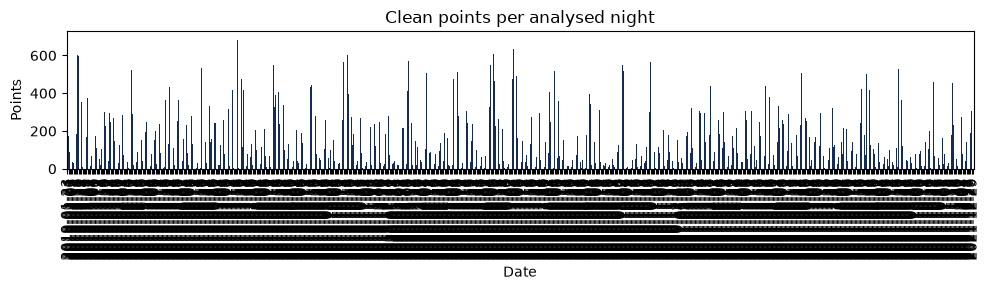

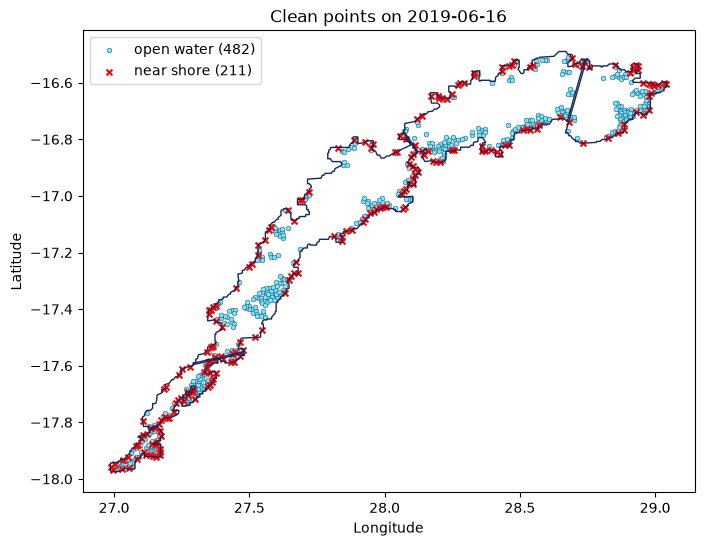

Duplicates left: 0 | missing values left: 0


In [ ]:
if len(clean_points):
    per_night = clean_points.groupby("Date").size()
    per_night.plot(kind="bar", figsize=(10, 3), color="#122B59", title="Clean points per analysed night")
    plt.ylabel("Points")
    plt.tight_layout()
    plt.show()

    busiest = per_night.idxmax()
    night = clean_points[clean_points["Date"] == busiest]
    fig, ax = plt.subplots(figsize=(9, 6))
    for polygon in lake_polygons:
        ring = np.asarray(polygon[0])
        ax.plot(ring[:, 0], ring[:, 1], color="#122B59", linewidth=1)
    shore = night[night["Near_Shore"]]
    water = night[~night["Near_Shore"]]
    ax.scatter(water["Longitude"], water["Latitude"], s=12, c="#77E6F6", edgecolor="#122B59", linewidth=0.3, label=f"open water ({len(water)})")
    ax.scatter(shore["Longitude"], shore["Latitude"], s=18, marker="x", c="red", label=f"near shore ({len(shore)})")
    ax.set_aspect(1 / np.cos(np.radians(night["Latitude"].mean())))
    ax.set_title(f"Clean points on {busiest}")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.legend()
    plt.show()

duplicates_left = int(clean_points.duplicated(["Date", "Pixel_Row", "Pixel_Col"]).sum()) if len(clean_points) else 0
missing_left = int(clean_points[["Latitude", "Longitude", "Radiance"]].isna().sum().sum()) if len(clean_points) else 0
print(f"Duplicates left: {duplicates_left} | missing values left: {missing_left}")

## 14. Ready for DBSCAN

DBSCAN needs one `[latitude, longitude]` pair per point, in radians, with `metric="haversine"`. This cell builds that array so the clustering notebook can start from the clean table:

```python
clean_points = pd.read_csv(OUTPUT_FOLDER / "kariba_clean_points.csv")
```

In [ ]:
X = np.radians(clean_points[["Latitude", "Longitude"]].to_numpy(dtype=float))
print("DBSCAN input shape (points x [lat, lon] in radians):", X.shape)

DBSCAN input shape (points x [lat, lon] in radians): (103574, 2)
